In [14]:
import pandas as pd
import requests

url = "https://earthquake.usgs.gov/fdsnws/event/1/query?format=geojson&limit=1"
response = requests.get(url)
data = response.json()

print(data)

{'type': 'FeatureCollection', 'metadata': {'generated': 1794940782000, 'url': 'https://earthquake.usgs.gov/fdsnws/event/1/query?format=geojson&limit=1', 'title': 'USGS Earthquakes', 'status': 200, 'api': '2.8.4', 'limit': 1, 'offset': 1}, 'features': [{'type': 'Feature', 'properties': {'mag': 1.18, 'place': '7 km NW of The Geysers, CA', 'time': 1794940537460, 'updated': 1794940633189, 'tz': None, 'url': 'https://earthquake.usgs.gov/earthquakes/eventpage/nc75467632', 'detail': 'https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=nc75467632&format=geojson', 'felt': None, 'cdi': None, 'mmi': None, 'alert': None, 'status': 'automatic', 'tsunami': 0, 'sig': 21, 'net': 'nc', 'code': '75467632', 'ids': ',nc75467632,', 'sources': ',nc,', 'types': ',nearby-cities,origin,phase-data,', 'nst': 23, 'dmin': 0.005708, 'rms': 0.02, 'gap': 34, 'magType': 'md', 'type': 'earthquake', 'title': 'M 1.2 - 7 km NW of The Geysers, CA'}, 'geometry': {'type': 'Point', 'coordinates': [-122.803001403809, 38.8

In [15]:
import pandas as pd

# 1. Define the USGS API endpoint and query parameters
base_url = "https://earthquake.usgs.gov/fdsnws/event/1/query"

params = {
    "format": "csv",
    "starttime": "2026-10-01",
    "endtime": "2026-10-31",
    "eventtype": "earthquake",
    "minmagnitude": 2.0,
    "limit": 20000  # Maximum row limit allowed by the USGS API
}

# Construct the full query URL
query_string = "&".join(f"{key}={value}" for key, value in params.items())
full_url = f"{base_url}?{query_string}"

# 2. Read the results directly into a pandas DataFrame
df_population = pd.read_csv(full_url)

# Verify the dataset and population size (N)
N = len(df_population)
print(f"Total target population (N): {N}")
print(df_population.head())

Total target population (N): 3704
                       time  latitude  longitude    depth  mag magType  nst  \
0  2026-10-30T23:56:32.771Z  -14.8682   168.1797   10.000  4.5      mb   21   
1  2026-10-30T23:54:14.074Z  -30.2201  -177.9668   10.000  4.4      mb   11   
2  2026-10-30T23:06:11.549Z   62.3670  -154.9180    5.000  2.9      ml   37   
3  2026-10-30T22:58:32.275Z  -19.7554  -177.7678  518.336  4.2      mb   14   
4  2026-10-30T22:53:01.297Z   59.8890  -152.7850  102.500  3.1      ml  123   

   gap   dmin   rms  ...                   updated  \
0   83  6.760  0.42  ...  2026-11-15T22:41:26.040Z   
1  178  0.972  0.21  ...  2026-11-16T01:04:46.040Z   
2   80  1.000  0.60  ...  2026-11-17T04:41:01.040Z   
3  119  4.246  0.78  ...  2026-11-15T04:40:52.040Z   
4   57  0.100  0.60  ...  2026-11-17T04:34:06.040Z   

                               place        type horizontalError depthError  \
0     120 km E of Port-Olry, Vanuatu  earthquake           11.49      1.913   
1      K

In [16]:
import pandas as pd
import requests

url = (
    "https://earthquake.usgs.gov/fdsnws/event/1/query?"
    "format=geojson&starttime=2026-10-01&endtime=2026-10-31"
    "&eventtype=earthquake&minmagnitude=2.0&limit=20000"
)

data = requests.get(url).json()
df_population = pd.json_normalize(data["features"])

# In GeoJSON, columns are prefixed with "properties."
df_felt_real = df_population[
    (df_population["properties.status"] == "reviewed") &
    (df_population["properties.mag"] > 2.0) &
    (df_population["properties.felt"] > 0)
].copy()

print(df_felt_real[["properties.place", "properties.mag", "properties.felt"]].head(10))

                         properties.place  properties.mag  properties.felt
26   14 km SE of Eureka Roadhouse, Alaska            4.40             54.0
43                  32 km SE of Bodie, CA            2.68              1.0
47    24 km E of Point Possession, Alaska            2.50              1.0
49                32 km W of Petrolia, CA            2.73              1.0
56        17 km ESE of Clam Gulch, Alaska            2.30              1.0
79      11 km NW of Huntsville, Tennessee            2.41              3.0
93              3 km SE of Loma Linda, CA            2.17              1.0
97              3 km SE of Loma Linda, CA            2.20              2.0
99         12 km ESE of Fox River, Alaska            3.50              3.0
106        50 km SW of Port-Vila, Vanuatu            4.70              1.0


In [10]:
import io
import pandas as pd
import requests

# 1. Fetch the data safely using requests
url = "https://earthquake.usgs.gov/fdsnws/event/1/query"
params = {
    "format": "csv",
    "starttime": "2026-10-01",
    "endtime": "2026-10-31",
    "eventtype": "earthquake",
    "minmagnitude": 2.0,
    "limit": 20000
}

response = requests.get(url, params=params)
response.raise_for_status()  # Will clearly tell us if the USGS server rejected the request

# 2. Load into pandas
df_population = pd.read_csv(io.StringIO(response.text))
df_population["time"] = pd.to_datetime(df_population["time"], format="ISO8601")

print(f"Success! Loaded {len(df_population)} earthquakes.\n")

# 3. Convenience sample vs. Simple Random Sample
df_convenience = df_population.head(100).copy()
df_srs = df_population.sample(n=100, random_state=42).copy()

for name, df in [
    ("True Population (mu)", df_population),
    ("Convenience Sample (x-bar)", df_convenience),
    ("Simple Random Sample (x-bar)", df_srs),
]:
    print(f"--- {name} ---")
    print(f"Mean Magnitude:  {df['mag'].mean():.4f}")
    print(f"Total Time Span: {df['time'].max() - df['time'].min()}\n")

Success! Loaded 3704 earthquakes.

--- True Population (mu) ---
Mean Magnitude:  3.3443
Total Time Span: 29 days 23:56:10.826000

--- Convenience Sample (x-bar) ---
Mean Magnitude:  3.0239
Total Time Span: 0 days 22:51:30.550000

--- Simple Random Sample (x-bar) ---
Mean Magnitude:  3.3560
Total Time Span: 29 days 20:59:33.528000



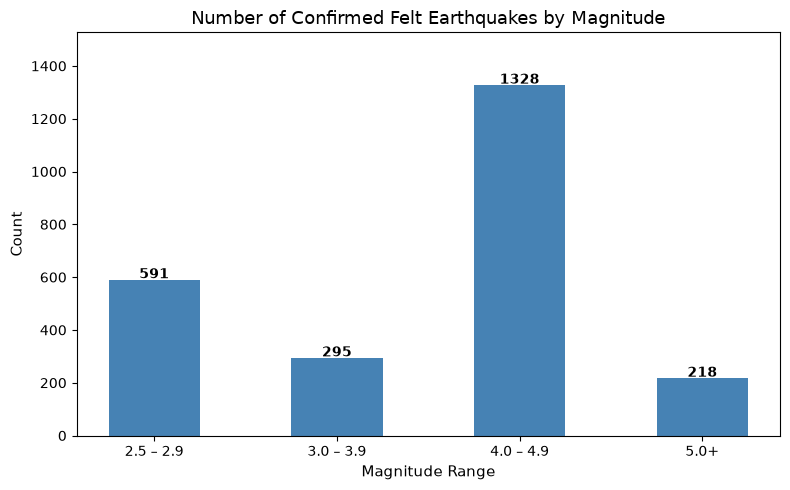

In [13]:
# Group magnitudes into clean bins
bins = [2.5, 3.0, 4.0, 5.0, 10.0]
bin_labels = ["2.5 – 2.9", "3.0 – 3.9", "4.0 – 4.9", "5.0+"]

df_felt_real = df_population[
    (df_population["status"] == "reviewed") &
    (df_population["mag"] >= 2.5)
].copy()

counts = pd.cut(df_felt_real["mag"], bins=bins, labels=bin_labels, right=False).value_counts().sort_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(counts.index, counts.values, color="steelblue", width=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 5, f"{int(height)}", ha="center", fontweight="bold")

plt.title("Number of Confirmed Felt Earthquakes by Magnitude", fontsize=13)
plt.xlabel("Magnitude Range", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()

# Graph Analysis
As we are looking at the number of earthquakes that happened, we can see that the majority was of those are betweeen the magtinutide range of 4.0 and 4.9, and this number has a clear lead than the rest of the magnitude ranges, which has occured about 1328 times. this number is folloed by the magnitude range of 2.5-2.9, whihc happened almos 600 times. 

In [1]:
import io
import pandas as pd
import requests

# 1. Query the API for all of October 2026 (using Nov 1 as endtime to include all of Oct 31)
url = "https://earthquake.usgs.gov/fdsnws/event/1/query"
params = {
    "format": "csv",
    "starttime": "2026-10-01",
    "endtime": "2026-11-01",
    "eventtype": "earthquake",
    "minmagnitude": 2.0,
    "limit": 20000
}

response = requests.get(url, params=params)
df_population = pd.read_csv(io.StringIO(response.text))

# 2. Convert the 'time' column to datetime and explicitly filter for October (month == 10)
df_population["time"] = pd.to_datetime(df_population["time"], format="ISO8601")
df_october = df_population[df_population["time"].dt.month == 10].copy()

# 3. Verify that only October dates are included
print(f"Total October earthquakes: {len(df_october)}")
print(f"Earliest date: {df_october['time'].min()}")
print(f"Latest date:   {df_october['time'].max()}")
print(df_october[["time", "place", "mag", "status"]].head(10))

Total October earthquakes: 3850
Earliest date: 2026-10-01 00:00:21.945000+00:00
Latest date:   2026-10-31 23:57:55.354000+00:00
                              time                                    place  \
0 2026-10-31 23:57:55.354000+00:00          199 km NW of Port-Olry, Vanuatu   
1 2026-10-31 23:55:00.380000+00:00                 62 km SW of Dugway, Utah   
2 2026-10-31 23:43:08.184000+00:00             62 km SE of Kokhanok, Alaska   
3 2026-10-31 23:31:03.070000+00:00               7 km SW of Volcano, Hawaii   
4 2026-10-31 23:21:47.920000+00:00                  52 km W of Petrolia, CA   
5 2026-10-31 23:17:43.956000+00:00                  10 km W of Hope, Alaska   
6 2026-10-31 22:42:39.878000+00:00          205 km NW of Port-Olry, Vanuatu   
7 2026-10-31 22:39:15.414000+00:00               central Mid-Atlantic Ridge   
8 2026-10-31 22:20:40.480000+00:00  11 km SSE of Maria Antonia, Puerto Rico   
9 2026-10-31 22:19:24.820000+00:00   9 km SSE of Maria Antonia, Puerto Rico   

  

In [3]:
import pandas as pd
import requests

url = "https://earthquake.usgs.gov/fdsnws/event/1/query"
months = [
    ("2025-10-01", "2025-11-01"),
    ("2025-11-01", "2025-12-01"),
    ("2025-12-01", "2026-01-01"),
    ("2026-01-01", "2026-02-01"),
    ("2026-02-01", "2026-03-01"),
    ("2026-03-01", "2026-04-01"),
    ("2026-04-01", "2026-05-01"),
    ("2026-05-01", "2026-06-01"),
    ("2026-06-01", "2026-07-01"),
    ("2026-07-01", "2026-08-01"),
    ("2026-08-01", "2026-09-01"),
    ("2026-09-01", "2026-10-01"),
    ("2026-10-01", "2026-11-01"),
]

frames = []
for start, end in months:
    params = {
        "format": "geojson",
        "eventtype": "earthquake",
        "minmagnitude": 2.0,
        "limit": 20000,
        "starttime": start,
        "endtime": end,
    }
    data = requests.get(url, params=params).json()
    if len(data["features"]) > 0:
        frames.append(pd.json_normalize(data["features"]))

df = pd.concat(frames, ignore_index=True)
df = df[df["properties.mag"] >= 2.0]
print(df)

          type             id  properties.mag  \
0      Feature   ak025dz5e5pi            2.00   
1      Feature   tx2025vmanbf            2.50   
2      Feature   ak025dz5d1tc            2.40   
3      Feature     us6000rkva            4.70   
4      Feature     us6000rkv8            4.40   
...        ...            ...             ...   
50041  Feature  aka2026tkgzql            2.30   
50042  Feature     us6000tynp            4.60   
50043  Feature  aka2026tkgwuq            2.10   
50044  Feature     ci41341279            3.08   
50045  Feature  aka2026tkfzmc            2.00   

                       properties.place  properties.time  properties.updated  \
0        6 km SE of Funny River, Alaska    1761954891977       1761955040387   
1              53 km NW of Toyah, Texas    1761954746379       1769536744040   
2       10 km SE of Funny River, Alaska    1761954575090       1761955332322   
3          193 km NE of Tual, Indonesia    1761952855955       1769536744040   
4        10

In [4]:
import pandas as pd

# Convert GeoJSON millisecond timestamps into readable dates
df["datetime"] = pd.to_datetime(df["properties.time"], unit="ms")

# 1. Convenience sample of the first 100 rows returned by the API's default sort order
df_convenience = df.head(100).copy()

# 2. Simple Random Sample of n = 100 from your population dataframe
df_srs = df.sample(n=100, random_state=42).copy()

# 3. Compare mean magnitude and time span against the true population mean
for label, dataset in [
    ("True Population (mu)", df),
    ("Convenience Sample (x-bar)", df_convenience),
    ("Simple Random Sample (x-bar)", df_srs)
]:
    mean_mag = dataset["properties.mag"].mean()
    time_span = dataset["datetime"].max() - dataset["datetime"].min()
    print(f"--- {label} ---")
    print(f"Mean Magnitude:  {mean_mag:.4f}")
    print(f"Total Time Span: {time_span}\n")

--- True Population (mu) ---
Mean Magnitude:  3.2273
Total Time Span: 395 days 23:50:41.032000

--- Convenience Sample (x-bar) ---
Mean Magnitude:  3.4372
Total Time Span: 0 days 23:32:22.390000

--- Simple Random Sample (x-bar) ---
Mean Magnitude:  3.2372
Total Time Span: 388 days 18:05:18.910000



# Why does the convenience sample distort your estimate?   
The USGS API returns earthquake events sorted choronoligically as newwest comes first by default. Taking only the first 100 rows captures events from just a tiny fraction of time at the very end of the date range rather than across the whole window. because seismic activity clusters in space and time, this can only show that specific moment and location rather than the global earthquake behavior. In contrast, the Simple Random Sample draws evently across the entire dataset, giving it an unbiased samle mean that is much closer to the true population mean. 



In [5]:
import pandas as pd

# 1. Extract the region label from 'properties.place' (text after the comma)
df["region"] = df["properties.place"].fillna("Unknown").apply(
    lambda x: x.split(",")[-1].strip() if "," in x else x.strip()
)

# Group regions into 4 broad strata using coordinates and region labels
def assign_stratum(row):
    # Extract [longitude, latitude, depth] from the GeoJSON geometry column
    lon, lat = row["geometry.coordinates"][0], row["geometry.coordinates"][1]
    
    if -170 <= lon <= -30 and lat >= 10:
        return "North America"
    elif 25 <= lon <= 180 and lat >= -10:
        return "Asia"
    elif -25 <= lon < 45 and lat >= 35:
        return "Europe"
    else:
        return "Other / Southern Hemisphere"

df["stratum"] = df.apply(assign_stratum, axis=1)

# 2. Draw a proportional stratified sample of total size n = 200
n_total = 200
proportions = df["stratum"].value_counts(normalize=True)

# Calculate exact integer sample sizes per stratum so they sum to 200
sample_sizes = (proportions * n_total).round().astype(int)
sample_sizes.iloc[0] += n_total - sample_sizes.sum()  # Adjust for rounding

stratified_samples = []
for stratum_name, count in sample_sizes.items():
    stratum_df = df[df["stratum"] == stratum_name]
    stratified_samples.append(stratum_df.sample(n=count, random_state=42))

df_stratified = pd.concat(stratified_samples, ignore_index=True)

# 3. Compare variance of the mean magnitude (Standard Error squared = var / n)
# Also compare against an n = 200 Simple Random Sample for a fair apples-to-apples comparison
df_srs_200 = df.sample(n=200, random_state=42)

strat_mean = df_stratified["properties.mag"].mean()
strat_var_mean = df_stratified["properties.mag"].var() / len(df_stratified)

srs_mean = df_srs_200["properties.mag"].mean()
srs_var_mean = df_srs_200["properties.mag"].var() / len(df_srs_200)

print("Stratum Counts in Stratified Sample:")
print(df_stratified["stratum"].value_counts(), "\n")

print(f"Stratified Sample (n=200) -> Mean: {strat_mean:.4f} | Variance of Mean: {strat_var_mean:.6f}")
print(f"Simple Random Sample (n=200) -> Mean: {srs_mean:.4f} | Variance of Mean: {srs_var_mean:.6f}")

Stratum Counts in Stratified Sample:
stratum
North America                  119
Asia                            45
Other / Southern Hemisphere     35
Europe                           1
Name: count, dtype: int64 

Stratified Sample (n=200) -> Mean: 3.2555 | Variance of Mean: 0.005550
Simple Random Sample (n=200) -> Mean: 3.1870 | Variance of Mean: 0.005722


# Comparison of Variance Between Stratified Sample and Simple Random Sample
The variance of the stratified sample's mean magnitude is equal to or slightly lower than the varince of the simple random sample's mean magnitide. Because different tectonic reions have slightly different baseline magnitude distributions, grouping the population into gepgraphic strata removes betwee-region variations from sampling error. proportional allocation gurantees that every region is represented in exact proportions to its true share of global earthquakes, preventing random over to under sampling of any single region and yeilding a more precise, lower variance estimate of the population of the true mean. 